**Prophet** is a framework for forecasting time series developed by Meta (former Facebook) in 2017. Its model is a regression on functions of time: a trend that may bend at a set of **changepoints**, Fourier terms for each seasonal period (the harmonic regression of Chapter 13), and dummy variables for holidays and special events.

- What Prophet adds is *automation*. It places the changepoints itself, regularizes all coefficients with priors so that a long list of terms does not overfit.
- Prophet is based on an *additive model* where non-linear trends are fit with yearly, weekly, and daily seasonality, plus holiday effects. 
- It works best with time series that have strong seasonal effects and several seasons of historical data. 
- Prophet is robust to missing data, shifts in the trend, and typically handles outliers well.

# Learning objectives

By the end of this lecture, you should be able to

1. write down the Prophet model $y(t) = g(t) + s(t) + h(t) + \varepsilon_t$, and explain each component: a piecewise linear or logistic trend, Fourier seasonality and holiday indicators;
2. explain how Prophet places potential changepoints and how the Laplace prior on the rate changes, controlled by `changepoint_prior_scale`, makes most of them vanish;
3. prepare a `ds`/`y` data frame, fit a model, build a future data frame and read the forecast, its intervals and its components;
4. add holidays and special events with windows around them, and country holidays;
5. fit a logistic trend with a carrying capacity `cap` (and a `floor`), and explain why these are inputs, not estimates;
6. choose between additive and multiplicative seasonality, and evaluate the forecasts on a test period and by rolling-origin cross-validation.

# Setup

Modules and functions used in this lecture.

| Module | Used for |
|---|---|
| `numpy` | `log`, `exp`, `sqrt`, `heaviside`, `linspace`, `random.seed` |
| `pandas` | `read_csv`, `DataFrame`, `groupby`, `resample`, `date_range`, `to_datetime`, `concat` |
| `matplotlib.pyplot` | `subplots`, `plot`, `bar`, `axvline` |
| `statsmodels.graphics.tsaplots` | `plot_acf` -- the autocorrelation of the residuals |
| `prophet` | `Prophet` -- the model; `make_future_dataframe`, `predict`, `plot`, `plot_components` |
| `prophet.plot` | `add_changepoints_to_plot` -- marks the changepoints on a forecast plot |
| `prophet.diagnostics` | `cross_validation` -- rolling-origin evaluation |

Prophet is not part of the standard scientific Python stack. Install it once with `pip install prophet` in the environment that runs these notebooks. It fits the model with the Stan library through `cmdstanpy`; both are installed with it.

In [ ]:
import logging

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf

logging.getLogger("prophet.plot").setLevel(logging.CRITICAL)   # silence the note that plotly is not installed
from prophet import Prophet
from prophet.plot import add_changepoints_to_plot
from prophet.diagnostics import cross_validation
logging.getLogger("cmdstanpy").disabled = True                 # silence the Stan progress messages of every fit

np.random.seed(8990)   # Prophet draws its uncertainty intervals from numpy's global generator

Self-defined functions carried over from earlier chapters: the run-sequence plot (Chapter 4), the MSE (Chapter 6), the MAPE (Chapter 12), and the MAE and accuracy table (Chapter 14).

In [2]:
def run_sequence_plot(y, x=None, title="", xlabel="time", ylabel="value",
                      ax=None, figsize=(9, 3), color="blue", **kwargs):
    "Plot a series against time and return the axes."
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
    if x is None:
        x = getattr(y, "index", np.arange(len(y)))
    ax.plot(x, y, color=color, lw=1, **kwargs)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.grid(alpha=0.3)
    return ax


def mse(observations, estimates):
    "Mean squared error between two equal-length sequences."
    observations = np.asarray(observations, dtype=float)
    estimates = np.asarray(estimates, dtype=float)
    if observations.shape != estimates.shape:
        raise ValueError(f"shape mismatch: {observations.shape} vs {estimates.shape}")
    return np.mean((observations - estimates) ** 2)


def mape(observations, estimates):
    "Mean absolute percentage error, in percent."
    observations = np.asarray(observations, dtype=float)
    estimates = np.asarray(estimates, dtype=float)
    return 100 * np.mean(np.abs((observations - estimates) / observations))


def mae(observations, estimates):
    "Mean absolute error between two equal-length sequences."
    observations = np.asarray(observations, dtype=float)
    estimates = np.asarray(estimates, dtype=float)
    return np.mean(np.abs(observations - estimates))


def accuracy(observations, estimates):
    "RMSE, MAE and MAPE of a forecast, as a dict (one row of a comparison table)."
    return {"RMSE": np.sqrt(mse(observations, estimates)), "MAE": mae(observations, estimates),
            "MAPE (%)": mape(observations, estimates)}

---

# The Prophet model

Prophet writes the series as the sum of three functions of time and a noise term:

$$y(t) = g(t) + s(t) + h(t) + \varepsilon_t,$$

where $g(t)$ is the **trend** (the non-periodic changes), $s(t)$ is the **seasonality** (the periodic changes, with one or more periods), $h(t)$ collects the **holiday and event effects**, and $\varepsilon_t$ is a normally distributed error. 

Time $t$ enters only through these functions. There are no lagged values of $y$, so Prophet is a regression on time, like the deterministic-trend and harmonic regressions of Chapter 13, not an ARIMA model. One consequence is that the model can be fitted to series with gaps and irregular spacing; another is that it assumes the errors $\varepsilon_t$ to be independent, which we will check.

## Trend component $g(t)$

The trend component models non-periodic changes in the value of the time series. Prophet provides two options for modeling the trend:
  - Piece-wise linear growth model.
  - Logistic growth model. 

### Piecewise linear growth model

A straight-line trend cannot follow a series whose growth rate changes. A piece-wise linear function can accommodate changes in the trend's direction over time. This is particularly useful for time series data exhibiting shifts in growth rates due to external factors or internal changes. This allows to capture and forecast time series trends that do not follow a specific form (linear or logistic).

- In a piece-wise linear trend model, the time series is divided into *segments*.
- In each segment, the trend is modeled as a linear function. 
- The points where the trend changes direction are called *change points*. 

Prophet lets the slope change at $S$ **changepoints** $s_1 < s_2 < \dots < s_S$:

$$g(t) = \bigl(k + \mathbf{a}(t)^\top \boldsymbol{\delta}\bigr)\, t + \bigl(m + \mathbf{a}(t)^\top \boldsymbol{\gamma}\bigr),$$

where $k$ is the initial growth rate, $m$ is the offset, $\delta_j$ is the change of the rate at changepoint $s_j$, and $\mathbf{a}(t)$ is a vector of indicators with $a_j(t) = 1$ if $t \ge s_j$ and $0$ otherwise. At time $t$, the rate is $k$ plus the sum of the $\delta_j$ of all changepoints already passed. The offsets $\gamma_j = -s_j \delta_j$ are not free parameters: they shift each new segment so that it starts where the previous one ended, and the trend stays continuous.

- Prophet allows users to specify the *maximum number* of potential change points or to let the algorithm automatically estimate it based on the data.
- Prophet automatically detects the change points, allowing the trend to adjust its slope at these points, hence capturing shifts in the trend's direction.

Users can adjust the flexibility of the model in capturing trend changes by tuning the change point *prior scale* parameter. 
   - A higher prior scale makes the model more sensitive to changes (allowing more flexibility).
   - A lower prior scale makes the model less sensitive to fluctuations (resulting in a smoother trend).

In [3]:
"Prophet's piecewise linear trend: rate k + sum of the deltas of the changepoints already passed."
def piecewise_linear_trend(t, k, m, changepoints, delta):
    t = np.asarray(t, dtype=float)
    s = np.asarray(changepoints, dtype=float)
    a = (t[:, None] >= s[None, :]).astype(float)        # a_j(t) = 1 once t has passed changepoint s_j
    gamma = -s * delta                                    # offset adjustments that keep g(t) continuous
    return (k + a @ delta) * t + (m + a @ gamma)

In [4]:
changepoints = np.array([3.0, 7.0, 11.0])
delta = np.array([0.1, -0.2, -0.1])          # rate changes at the three changepoints
k, m = 0.3, 4.0                              # initial rate and offset

t_grid = np.linspace(0, 15, 301)
g = piecewise_linear_trend(t_grid, k, m, changepoints, delta)
rates = k + np.concatenate([[0], np.cumsum(delta)])

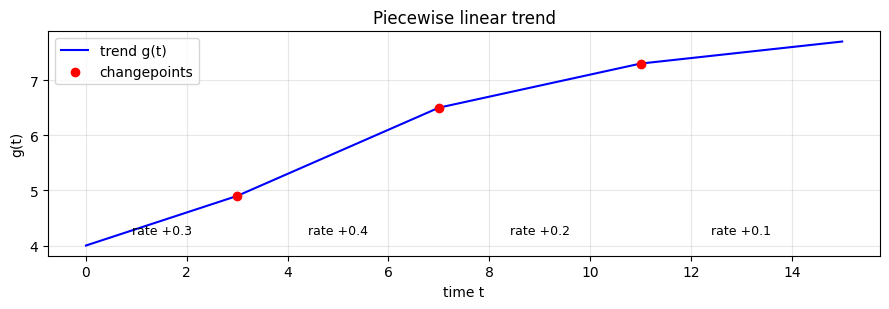

In [5]:
_, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(t_grid, g, color="blue", label="trend g(t)")
ax.scatter(changepoints, piecewise_linear_trend(changepoints, k, m, changepoints, delta),
           color="red", zorder=3, label="changepoints")
for left, right, rate in zip(np.r_[0, changepoints], np.r_[changepoints, 15], rates):
    ax.text((left + right) / 2, 4.2, f"rate {rate:+.1f}", ha="center", fontsize=9)
ax.set(title="Piecewise linear trend", xlabel="time t", ylabel="g(t)")
ax.grid(alpha=0.3); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

The rate is $0.3$ until $t = 3$, then $0.3 + 0.1 = 0.4$, then $0.4 - 0.2 = 0.2$ after $t = 7$, and $0.2 - 0.1 = 0.1$ after $t = 11$. The trend bends at each changepoint but never jumps.

> **Try it yourself**
>
> Set `gamma = 0` inside `piecewise_linear_trend` (that is, drop the offset adjustments) and plot again: the trend now jumps at every changepoint. Then change `delta` to see how the slopes respond.

**How Prophet chooses the changepoints.** Prophet does not search for the best changepoint dates. It places a large number of *potential* changepoints, 25 by default, evenly over the first 80% of the history, and estimates a $\delta_j$ for each of them. To keep most of them at zero, it puts a **Laplace prior** on the rate changes,

$$\delta_j \sim \text{Laplace}(0, \tau),$$

where $\tau$ is the argument `changepoint_prior_scale` (default $0.05$). The Laplace prior is the Bayesian form of the L1 (lasso) penalty: it pulls small $\delta_j$ to (nearly) zero, so only a few changepoints change the slope noticeably. A larger $\tau$ allows more and larger slope changes, so a more flexible trend; a smaller $\tau$ gives a stiffer trend.

**The trend in the forecast period.** Beyond the data, the trend continues with the last estimated rate. To express the uncertainty about future rate changes, Prophet simulates future changepoints with the same frequency and the same average size $|\delta_j|$ as in the history. This is the source of the widening trend uncertainty in the forecast intervals.

### Logistic growth model

Some series cannot grow forever: 
- Grows rapidly when it's small.
- Grows slowlier as it approaches a maximum limit (*carrying capacity*) that it cannot exceed.
- Eventually levels off when the carrying capacity is reached (*saturating growth*).

For such series, Prophet offers a **logistic** trend:

$$g(t) = \frac{C}{1 + e^{-k(t - m)}},$$

where $C$ is the **carrying capacity** (the maximum value), $k$ is the growth rate, and $m$ is the time at which the trend is halfway to $C$. The growth is fastest at $t = m$ and slows down as $g(t)$ approaches $C$: the trend **saturates**. In Prophet, the rate $k$ may again change at changepoints, and $C$ may vary with time; $C$ is supplied by the user in a column `cap`, it is not estimated.

In [6]:
def logistic_trend(t, C, k, m):
    "Logistic growth with carrying capacity C, growth rate k and midpoint m."
    return C / (1 + np.exp(-k * (np.asarray(t, dtype=float) - m)))

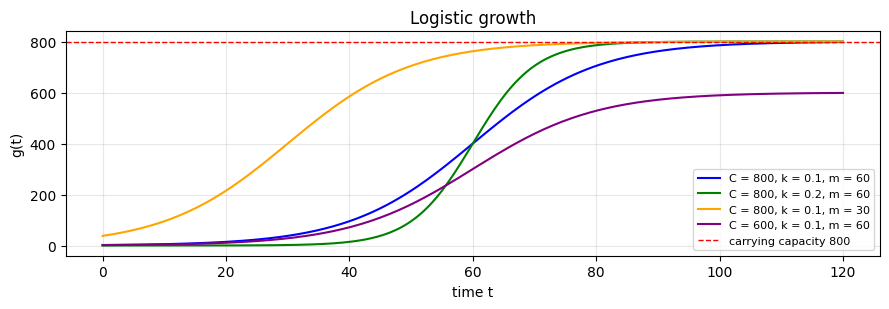

In [7]:
t_grid = np.linspace(0, 120, 241)
_, ax = plt.subplots(figsize=(9, 3.2))
for C, k, m, color in [(800, 0.1, 60, "blue"), (800, 0.2, 60, "green"), (800, 0.1, 30, "orange"),
                       (600, 0.1, 60, "purple")]:
    ax.plot(t_grid, logistic_trend(t_grid, C, k, m), color=color, label=f"C = {C}, k = {k}, m = {m}")
ax.axhline(800, color="red", ls="--", lw=1, label="carrying capacity 800")
ax.set(title="Logistic growth", xlabel="time t", ylabel="g(t)")
ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

A larger $k$ (green) makes the S-curve steeper, a smaller $m$ (orange) shifts it earlier, and a smaller $C$ (purple) lowers the ceiling. Every curve passes $C/2$ at $t = m$.

Prophet also has `growth="flat"`, a constant trend, for series whose level does not change.

## Seasonality component $s(t)$: Fourier series

Prophet uses Fourier series to model these periodic changes, allowing for flexibility in capturing seasonality.
Each seasonal component with period $P$ is a Fourier series, exactly the harmonic terms of Chapter 13:

$$s(t) = \sum_{n=1}^{N} \left( a_n \cos\frac{2\pi n t}{P} + b_n \sin\frac{2\pi n t}{P} \right),$$

where $P$ is the period in days ($365.25$ for yearly, $7$ for weekly, $1$ for daily seasonality), $N$ is the number of harmonics (the **Fourier order**), and $a_n, b_n$ are coefficients estimated from the data. A larger $N$ allows a more detailed seasonal shape, at the cost of $2N$ parameters. Prophet's defaults are $N = 10$ for the yearly, $N = 3$ for the weekly and $N = 4$ for the daily seasonality. It switches each one on automatically when the data allow it: yearly seasonality needs at least two years of data, weekly seasonality needs observations less than a week apart, and daily seasonality needs observations within a day.

The coefficients get a normal prior, $a_n, b_n \sim \mathcal{N}(0, \sigma^2)$, with $\sigma$ set by `seasonality_prior_scale` (default 10, which hardly restricts anything). This is a ridge penalty: a smaller value shrinks the seasonal effects towards zero.

## Holidays and events

Holidays, sporting events and promotions are not periodic, but their dates are known in advance. Prophet represents each of them by an indicator variable:

$$h(t) = \sum_{i} \kappa_i \, \mathbb{I}(t \in D_i),$$

where $D_i$ is the set of times corresponding to holiday event $i$, $\mathbb{I}(\cdot)$ is the indicator function (1 if $t$ is one of the dates, 0 otherwise), and $\kappa_i$ is the effect of the event, estimated from the data. An event may have a **window**: with `lower_window=-1` and `upper_window=1`, the day before and the day after also get indicators, *each with its own coefficient*. The prior is again normal, $\kappa_i \sim \mathcal{N}(0, \nu^2)$, with $\nu$ set by `holidays_prior_scale` (default 10).

## Seasonal and holiday effects adjustment

- Like for piece-wise linear trend, Prophet can adjust for overfitting or underfitting of seasonal and holiday effects by changing a *prior scale* parameter. 
- A *larger* prior scale allows the model to fit larger seasonal fluctuations.
- A *smaller* scale regularizes the model, preventing it from overfitting seasonal and holiday effects.

## Fitting the model

Every component is linear in its parameters, given the changepoint dates. Prophet first rescales $y$ by its maximum absolute value (so the prior scales do not depend on the units), then finds the **maximum a posteriori** (MAP) estimate: the parameters that maximize the likelihood times the priors, which for the normal and Laplace priors is a least-squares fit with ridge and lasso penalties. The optimization runs in [Stan](https://mc-stan.org/), a C++ library for statistical models, with the L-BFGS algorithm, and takes about a second. With `mcmc_samples=` set to a positive number, Prophet instead samples the full posterior by Markov chain Monte Carlo (MCMC), which is slower but also gives uncertainty for the seasonal and holiday components.

---

# Prophet in Python: electricity load in PJM East

## The data

Prophet takes a data frame with two columns: `ds`, the date stamps (dates `YYYY-MM-DD` or times `YYYY-MM-DD HH:MM:SS`), and `y`, the numeric values to forecast. Other column names are not recognized, so a series must be renamed first.

Our example is the electricity load of the PJM East region from Chapter 14, in the file `data/PJME_hourly.csv`: hourly values in megawatts (MW), from 2002 to August 2018. It suits Prophet well: three seasonal cycles (yearly, weekly and daily), holidays, and a level that drifts slowly over the years.

For most of this section, we work with the **daily mean load**. A Prophet fit takes under two seconds on the 6,000 daily values, but about two minutes on the 145,000 hourly values, and this section fits the model several dozen times. We return to the hourly data at the end of the section, for the daily cycle.

In [8]:
pjme_raw = pd.read_csv("data/PJME_hourly.csv", index_col="Datetime", parse_dates=True)
pjme_hourly = pjme_raw["PJME_MW"].groupby(level=0).mean().sort_index() / 1000   # GW; averages the repeated DST hour
hours = pjme_hourly.resample("D").count()
daily = pjme_hourly.resample("D").mean()[hours >= 23]                          # drops the last day, which has one hour

load = pd.DataFrame({"ds": daily.index, "y": daily.to_numpy()})
print(load.head(3), "\n")
print(f"hourly values: {len(pjme_hourly)},  from {pjme_hourly.index[0]} to {pjme_hourly.index[-1]}")
print(f"days: {len(load)},  from {load['ds'].iloc[0].date()} to {load['ds'].iloc[-1].date()}")
print(f"missing days: {len(pd.date_range(load['ds'].iloc[0], load['ds'].iloc[-1]).difference(load['ds']))}")

          ds          y
0 2002-01-01  31.080739
1 2002-01-02  34.261542
2 2002-01-03  34.511875 

hourly values: 145362,  from 2002-01-01 01:00:00 to 2018-08-03 00:00:00
days: 6058,  from 2002-01-01 to 2018-08-02
missing days: 0


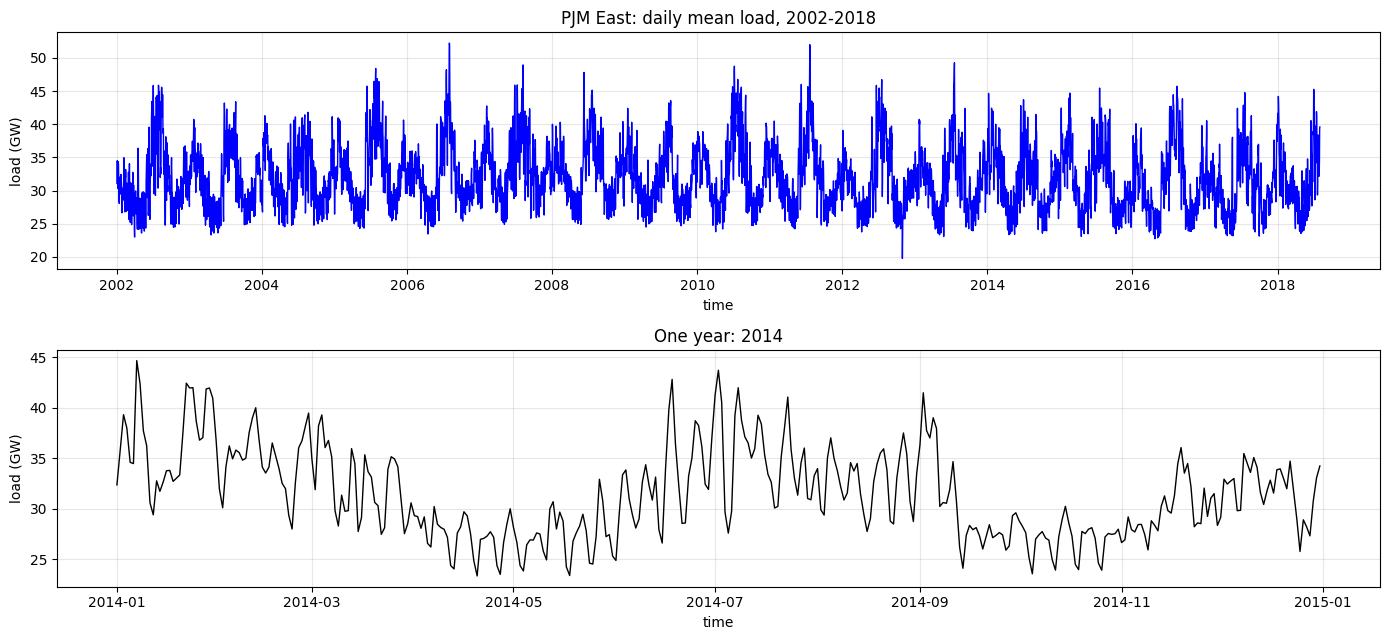

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(14, 6.5))
run_sequence_plot(load["y"], x=load["ds"], ax=axes[0], ylabel="load (GW)",
                  title="PJM East: daily mean load, 2002-2018")
year = load[load["ds"].dt.year == 2014]
run_sequence_plot(year["y"], x=year["ds"], ax=axes[1], ylabel="load (GW)", color="black",
                  title="One year: 2014")
plt.tight_layout(); plt.show()

The daily series shows two of the three cycles of Chapter 14:

- a **yearly** cycle with two peaks, a high one in July and August (air conditioning) and a lower one in January and February (heating), and troughs of about 25 GW in spring and autumn;
- a **weekly** cycle, the regular zigzag in the 2014 panel: the weekend days are a few gigawatts below the weekdays.

The level drifts only a little over the years. The lowest day, below 20 GW, is 30 October 2012, when Hurricane Sandy cut power to millions of customers. The day-to-day variation within each season is weather: a hot week in summer or a cold week in winter raises the load by 5 to 10 GW.

## Train/test split

As in Chapter 14, we train on 2002-2014 and hold out everything from 1 January 2015 on, three years and seven months. Unlike a tree ensemble, Prophet extrapolates its trend, so the long test period also tests the trend.

In [10]:
split = pd.Timestamp("2015-01-01")
train = load[load["ds"] < split].copy()
test = load[load["ds"] >= split].copy()
print(f"training: {train['ds'].iloc[0].date()} to {train['ds'].iloc[-1].date()}  ({len(train)} days)")
print(f"test:     {test['ds'].iloc[0].date()} to {test['ds'].iloc[-1].date()}  ({len(test)} days)")

training: 2002-01-01 to 2014-12-31  (4748 days)
test:     2015-01-01 to 2018-08-02  (1310 days)


## Fitting and forecasting

We create a `Prophet` object with its options, then fit it to the training data. The options we set explicitly are

- `growth="linear"`, the piecewise linear trend (the alternatives are `"logistic"` and `"flat"`);
- `seasonality_mode="additive"`, as in the model equation above (the alternative is `"multiplicative"`, see below);
- `interval_width=0.90`, the coverage of the prediction intervals (default 0.80).

Everything else keeps its default: 25 potential changepoints in the first 80% of the data, `changepoint_prior_scale=0.05`, and yearly and weekly seasonality. The data are daily, so there is no daily seasonality.

In [11]:
model = Prophet(growth="linear", seasonality_mode="additive", interval_width=0.90)
model.fit(train)
print("seasonalities:", {name: (s["period"], s["fourier_order"]) for name, s in model.seasonalities.items()})
print("number of potential changepoints:", len(model.changepoints))

seasonalities: {'yearly': (365.25, 10), 'weekly': (7, 3)}
number of potential changepoints: 25


To forecast, Prophet needs a data frame with a `ds` column holding the dates to predict. `make_future_dataframe(periods=len(test), freq="D")` returns the dates of the training period followed by as many days as the test period has (`include_history=False` would drop the training dates). `predict` fills in, for each date, the forecast `yhat` with its interval `yhat_lower`, `yhat_upper`, and every component of the model.

In [12]:
future = model.make_future_dataframe(periods=len(test), freq="D")
forecast = model.predict(future)
in_test = forecast["ds"] >= split
print(f"rows in future: {len(future)} = {len(train)} training + {len(test)} test days;",
      "test dates match:", forecast.loc[in_test, "ds"].reset_index(drop=True).equals(test["ds"].reset_index(drop=True)))
print("columns of forecast:", list(forecast.columns), "\n")
print(forecast[["ds", "yhat", "yhat_lower", "yhat_upper", "trend", "weekly", "yearly"]].tail(3).round(3))

rows in future: 6058 = 4748 training + 1310 test days; test dates match: True
columns of forecast: ['ds', 'trend', 'yhat_lower', 'yhat_upper', 'trend_lower', 'trend_upper', 'additive_terms', 'additive_terms_lower', 'additive_terms_upper', 'weekly', 'weekly_lower', 'weekly_upper', 'yearly', 'yearly_lower', 'yearly_upper', 'multiplicative_terms', 'multiplicative_terms_lower', 'multiplicative_terms_upper', 'yhat'] 

             ds    yhat  yhat_lower  yhat_upper   trend  weekly  yearly
6055 2018-07-31  37.866      32.890      42.952  30.411   1.216   6.239
6056 2018-08-01  37.801      32.598      43.019  30.410   1.266   6.125
6057 2018-08-02  37.497      32.249      42.734  30.409   1.080   6.008


In the additive model, the forecast is the sum of its components: on 2 August 2018, for instance, $\hat y = 30.409 + 1.080 + 6.008 = 37.497$ GW (trend + weekly + yearly). There are no holidays yet, so $h(t) = 0$. The columns ending in `_lower` and `_upper` hold the bounds of the 90% intervals.

`Prophet.plot` draws the data (black dots), the fitted values and forecast (blue line) and the interval (light blue band). We add the test data in orange.

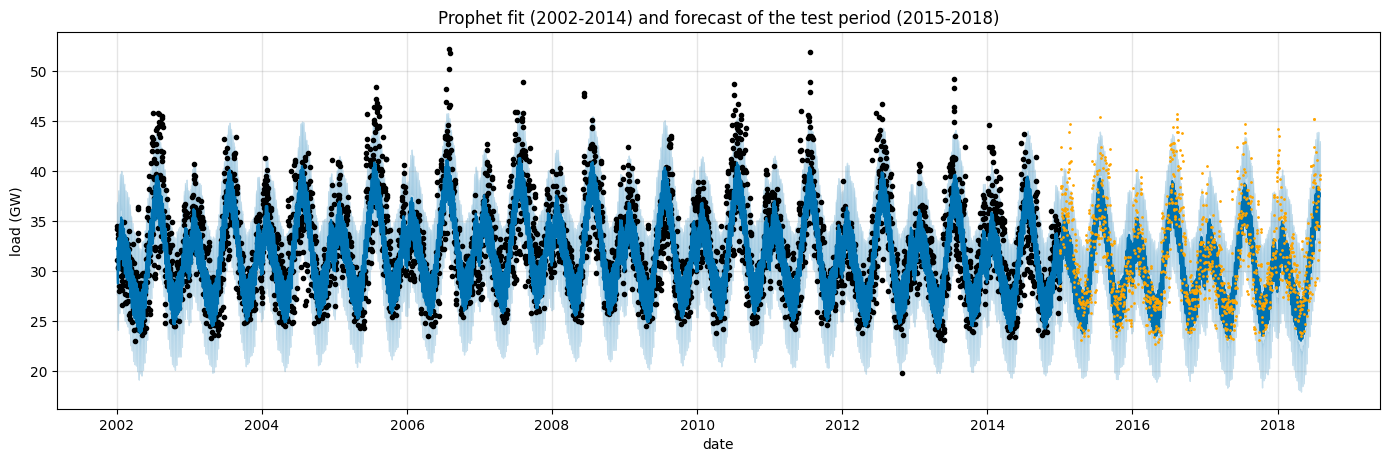

In [13]:
fig = model.plot(forecast, figsize=(14, 4.5), xlabel="date", ylabel="load (GW)")
ax = fig.gca()
ax.plot(test["ds"], test["y"], ".", color="orange", ms=2, label="test data")
ax.set_title("Prophet fit (2002-2014) and forecast of the test period (2015-2018)")
plt.show()

The fit follows the yearly double peak and the weekly cycle (the thick look of the blue line), but not the hottest summer days and the coldest winter days, which lie far above the band: they are weather, and no function of time can predict them. In the test period, the forecast repeats the same yearly and weekly pattern on a slowly falling trend, and most of the orange test days fall inside the band.

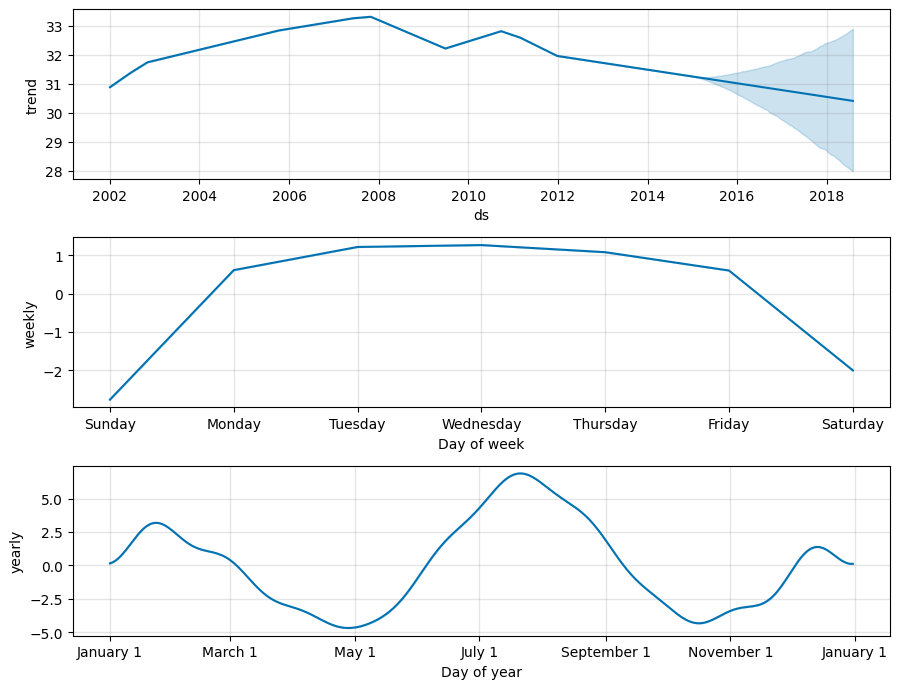

In [14]:
fig = model.plot_components(forecast, figsize=(9, 7))
plt.show()

`plot_components` shows each component on its own, in GW:

- **Trend**: a rise from 31 GW in 2002 to 33 GW in 2008, a drop in the recession of 2008-2009, a short recovery in 2010, and a slow decline from 2011 on. In the test period, the trend continues the decline, from 31.2 GW at the start of 2015 to 30.4 GW in August 2018. The shaded band is the trend uncertainty from simulated future changepoints, about $\pm 2.5$ GW after three and a half years. It is the only uncertainty shown here, since the seasonal components are point estimates.
- **Weekly**: Tuesday to Thursday are about 1.2 GW above the average day, Monday and Friday 0.6 GW, Saturday $-2.0$ GW and Sunday $-2.8$ GW. The weekend is about 4 GW below the middle of the week.
- **Yearly**: the main peak in late July ($+6.9$ GW), a lower winter peak in late January ($+3.2$ GW), troughs in early May ($-4.6$ GW) and late October ($-4.3$ GW), and a small bump in December. From the May trough to the July peak, the load rises by more than 11 GW.

With `plotly` installed, the same two figures can be drawn as interactive plots:

```python
from prophet.plot import plot_plotly, plot_components_plotly

plot_plotly(model, forecast)
plot_components_plotly(model, forecast)
```

## Accuracy on the test period

As a benchmark, we use the **mean training load for each combination of month and day of the week**, a lookup table of $12 \times 7 = 84$ averages, the daily version of the benchmark of Chapter 14. Besides the accuracy, we report the share of test days inside the 90% interval.

In [15]:
keys = lambda d: [d["ds"].dt.month, d["ds"].dt.dayofweek]
profile = train.groupby(keys(train))["y"].mean()
benchmark = profile.reindex(pd.MultiIndex.from_arrays(keys(test))).to_numpy()

def coverage(observations, fc):
    "Share of the observations inside the forecast interval, in percent."
    y = np.asarray(observations, dtype=float)
    return 100 * np.mean((y >= fc["yhat_lower"].to_numpy()) & (y <= fc["yhat_upper"].to_numpy()))

table = pd.DataFrame({"month x weekday means": accuracy(test["y"], benchmark),
                      "Prophet": {**accuracy(test["y"], forecast.loc[in_test, "yhat"]),
                                  "coverage 90% (%)": coverage(test["y"], forecast[in_test])}}).T
table.round(3)

,RMSE,MAE,MAPE (%),coverage 90% (%)
month x weekday means,3.488,2.821,9.145,NaN
Prophet,3.272,2.429,7.453,85.191


Prophet's daily forecasts are off by 3.3 GW (RMSE) or 7.5% (MAPE) over three and a half years. The lookup table of 84 averages has an RMSE of 3.5 GW and a MAPE of 9.1%. Part of the difference is the trend: the table averages 2002-2014, which lies above the level of 2015-2018, while Prophet's falling trend follows the lower level. The smooth Fourier seasonality also helps, since a monthly step jumps at every month boundary. The 90% intervals cover 85% of the test days, a little less than they should.

## Are the errors independent?

The model assumes independent errors $\varepsilon_t$. The residuals $y_t - \hat y_t$ of the training period let us check it with the autocorrelation function of Chapter 9.

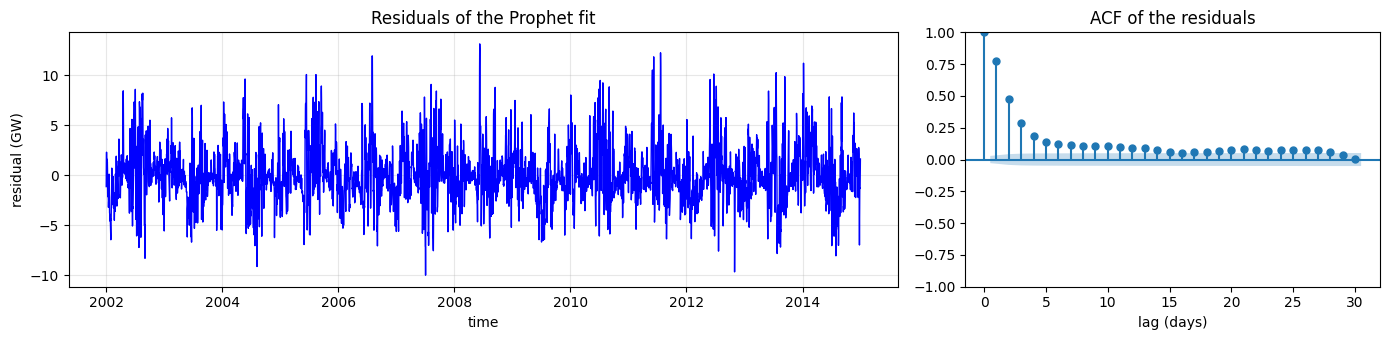

lag-1 autocorrelation: 0.78
share of the training days inside the 90% interval: 89.1%


In [16]:
fitted = forecast[~in_test]
resid = train["y"].to_numpy() - fitted["yhat"].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(14, 3.5), gridspec_kw={"width_ratios": [2, 1]})
run_sequence_plot(resid, x=train["ds"], ax=axes[0], ylabel="residual (GW)", title="Residuals of the Prophet fit")
plot_acf(resid, lags=30, ax=axes[1], title="ACF of the residuals")
axes[1].set_xlabel("lag (days)")
plt.tight_layout(); plt.show()
print(f"lag-1 autocorrelation: {pd.Series(resid).autocorr(1):.2f}")
print(f"share of the training days inside the 90% interval: {coverage(train['y'], fitted):.1f}%")

The residuals are far from independent. The lag-1 autocorrelation is about 0.8, and the ACF decays only over about five days: a day hotter or colder than usual for the season is usually followed by another one, because heat waves and cold spells last several days. In the training period, 89% of the days fall inside the 90% band, as they should, but the errors come in runs. Two remedies use this information. An ARIMA model for the residuals (Chapters 11 to 13) improves the forecasts a few days ahead. A temperature series added as an extra regressor, with `m.add_regressor("temperature")`, explains the weather itself, but then the forecast needs a temperature forecast.

---

# Holidays and special events

To add events, we build a data frame with a column `holiday` (the name of the event) and a column `ds` (its dates), with one row per occurrence. It must list the occurrences in the history and in the forecast period: an event that does not appear in the future dates has no effect on the forecast. Optional columns `lower_window` and `upper_window` extend each occurrence to the days around it, and each day of the window gets its own coefficient.

Chapter 14 found that the load drops most on the holidays when businesses close, and on days around them that are not federal holidays at all. We define two events by hand:

- `thanksgiving`: the fourth Thursday of November, with `upper_window=1` for the Friday after it;
- `christmas`: 25 December, with `lower_window=-1` and `upper_window=7`, which covers Christmas Eve and the whole week up to New Year's Day.

In [17]:
years = range(2002, 2019)
thanksgiving = [pd.date_range(f"{y}-11-01", f"{y}-11-30", freq="W-THU")[3] for y in years]
events = pd.concat([
    pd.DataFrame({"holiday": "thanksgiving", "ds": pd.to_datetime(thanksgiving),
                  "lower_window": 0, "upper_window": 1}),
    pd.DataFrame({"holiday": "christmas", "ds": pd.to_datetime([f"{y}-12-25" for y in years]),
                  "lower_window": -1, "upper_window": 7}),
], ignore_index=True)

model_ev = Prophet(holidays=events, growth="linear", seasonality_mode="additive", interval_width=0.90)
forecast_ev = model_ev.fit(train).predict(future)

season = forecast_ev[(forecast_ev["ds"] >= "2015-11-25") & (forecast_ev["ds"] <= "2016-01-02")]
season = season[(season["thanksgiving"] != 0) | (season["christmas"] != 0)]
shown = pd.DataFrame({"day": season["ds"].dt.strftime("%a %d %b %Y"),
                      "observed": test.set_index("ds")["y"].reindex(season["ds"]).to_numpy(),
                      "Prophet": forecast.set_index("ds")["yhat"].reindex(season["ds"]).to_numpy(),
                      "Prophet + events": season["yhat"].to_numpy(),
                      "thanksgiving": season["thanksgiving"].to_numpy(),
                      "christmas": season["christmas"].to_numpy()})
print("Holiday season 2015 (test period), load in GW:")
print(shown.round(2).to_string(index=False))

Holiday season 2015 (test period), load in GW:
            day  observed  Prophet  Prophet + events  thanksgiving  christmas
Thu 26 Nov 2015     26.00    30.46             26.71         -4.16       0.00
Fri 27 Nov 2015     25.51    30.19             27.94         -2.59       0.00
Thu 24 Dec 2015     26.50    32.68             30.75          0.00      -2.87
Fri 25 Dec 2015     24.47    32.09             29.10          0.00      -3.93
Sat 26 Dec 2015     24.81    29.38             28.55          0.00      -1.77
Sun 27 Dec 2015     25.10    28.53             28.52          0.00      -0.96
Mon 28 Dec 2015     29.25    31.84             31.83          0.00      -0.98
Tue 29 Dec 2015     29.84    32.39             32.31          0.00      -1.07
Wed 30 Dec 2015     29.01    32.40             32.33          0.00      -1.07
Thu 31 Dec 2015     27.80    32.21             31.43          0.00      -1.83
Fri 01 Jan 2016     27.95    31.74             29.01          0.00      -3.71


Each day of an event window has its own coefficient. Thanksgiving lowers the load by 4.2 GW and the Friday after it by 2.6 GW. The Christmas window lowers the load by 2.9 GW on Christmas Eve, 3.9 GW on Christmas Day, 1.8 GW on 26 December, about 1 GW on the working days between Christmas and New Year, 1.8 GW on New Year's Eve and 3.7 GW on New Year's Day.

In 2015, these effects bring the Thanksgiving forecasts close to the observed load (26.7 against 26.0 GW, where the model without events forecast 30.5). Christmas Day is still forecast 4.6 GW too high. The coefficient is an average over years in which Christmas fell on different days of the week, and a Christmas on a Friday, as in 2015, makes a long weekend. December 2015 was also unusually warm in the eastern US: the load stayed 2.5 to 3.5 GW below the forecast even on the working days of 28 to 30 December, which no holiday effect explains.

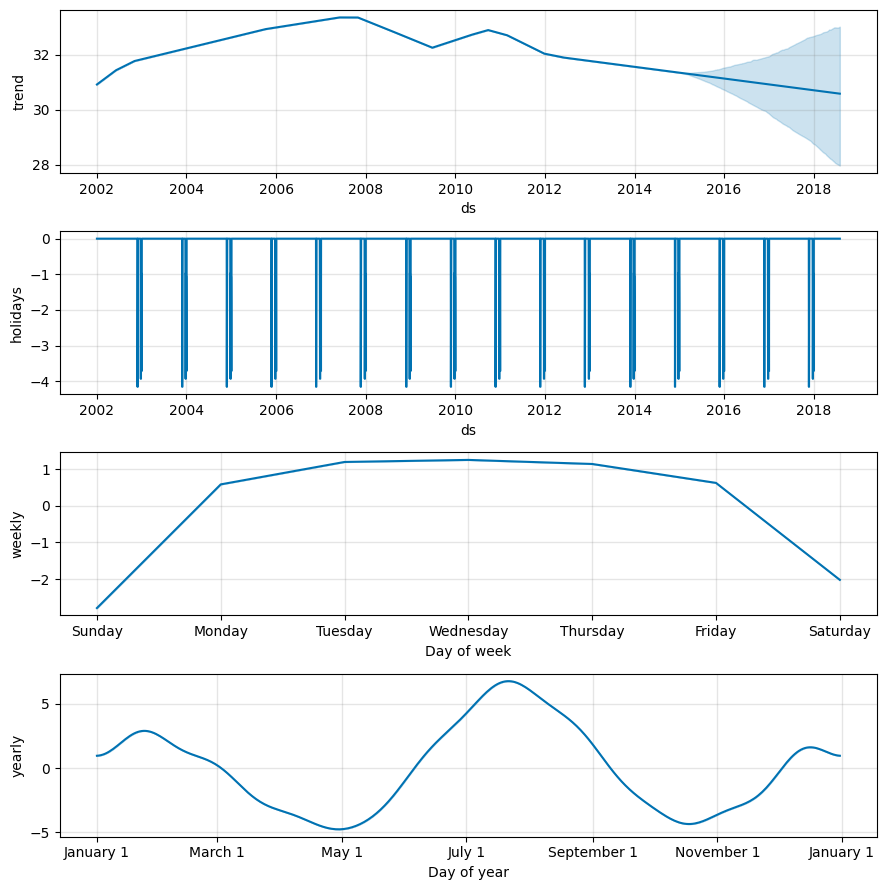

In [18]:
fig = model_ev.plot_components(forecast_ev, figsize=(9, 9))
plt.show()

The component plot now has a `holidays` panel. Every year, it shows a dip of about 4 GW at Thanksgiving and a group of dips over Christmas and New Year. The events are listed up to 2018, so they repeat in the forecast period. The trend, weekly and yearly panels hardly change: the events explain a few days of each year, not the season.

## Country holidays

Prophet has the public holidays of many countries built in, through the `holidays` package. `add_country_holidays(country_name="US")` adds the US federal holidays to any events given by hand. The list of supported countries and their codes is in the [documentation of the `holidays` package](https://github.com/vacanza/python-holidays/).

We fit a model with the US holidays alone, look at the estimated effect of each holiday, and then compare four models on the test period: without holidays, with our two events, with the US holidays, and with both.

In [19]:
model_us = Prophet(interval_width=0.90)
model_us.add_country_holidays(country_name="US")
forecast_us = model_us.fit(train).predict(future)

effects = {name: forecast_us.loc[forecast_us[name] != 0, name].mean() for name in model_us.train_holiday_names}
print("average effect on the daily load (GW):")
print(pd.Series(effects).sort_values().round(2).to_string())

average effect on the daily load (GW):
Thanksgiving Day              -4.08
Labor Day                     -3.85
Christmas Day                 -3.46
New Year's Day                -3.14
Independence Day              -2.98
Christmas Day (observed)      -2.97
New Year's Day (observed)     -2.90
Memorial Day                  -2.21
Independence Day (observed)   -1.95
Veterans Day (observed)       -0.80
Martin Luther King Jr. Day    -0.48
Veterans Day                  -0.13
Columbus Day                   0.07
Washington's Birthday          0.27


In [20]:
model_both = Prophet(holidays=events, interval_width=0.90)
model_both.add_country_holidays(country_name="US")
forecast_both = model_both.fit(train).predict(future)

on_holiday = (forecast_us.loc[in_test, "holidays"] != 0).to_numpy()   # US holidays in the test period
rows = {}
for name, fc in [("no holidays", forecast), ("events", forecast_ev), ("US holidays", forecast_us),
                 ("events + US holidays", forecast_both)]:
    p = fc.loc[in_test, "yhat"].to_numpy()
    rows[name] = {**accuracy(test["y"], p),
                  "MAPE US holidays (%)": mape(test["y"][on_holiday], p[on_holiday]),
                  "MAPE other days (%)": mape(test["y"][~on_holiday], p[~on_holiday])}
print(f"US holidays in the test period: {on_holiday.sum()} days")
pd.DataFrame(rows).T.round(3)

US holidays in the test period: 39 days


,RMSE,MAE,MAPE (%),MAPE US holidays (%),MAPE other days (%)
no holidays,3.272,2.429,7.453,11.472,7.330
events,3.239,2.418,7.430,10.801,7.327
US holidays,3.240,2.410,7.395,9.478,7.331
events + US holidays,3.222,2.404,7.382,9.378,7.320


The estimated holiday effects reproduce the finding of Chapter 14. The holidays when most businesses close lower the daily load by 2 to 4 GW: Thanksgiving, Labor Day, Christmas, New Year's Day, Independence Day and Memorial Day. On Martin Luther King Jr. Day, Veterans Day, Columbus Day and Washington's Birthday, most businesses stay open, and the effect is between $-0.5$ and $+0.3$ GW, practically zero. In Chapter 14, a single 0/1 holiday feature had to serve both groups. Prophet gives each holiday its own coefficient, so it separates them without further work.

On the 39 federal holidays of the test period, the MAPE falls from 11.5% without holidays to 10.8% with our two events, 9.5% with the US holidays, and 9.4% with both. The other days are unaffected. Over the whole test period, the gain is small, because holidays are only 3% of the days, and the holidays are still forecast worse than ordinary days.

---

# Trend changepoints

## Which changepoints are used?

Back to the model without holidays. `add_changepoints_to_plot` marks the changepoints whose rate change $|\delta_j|$ exceeds a threshold. With `threshold=0`, it shows all 25 potential changepoints.

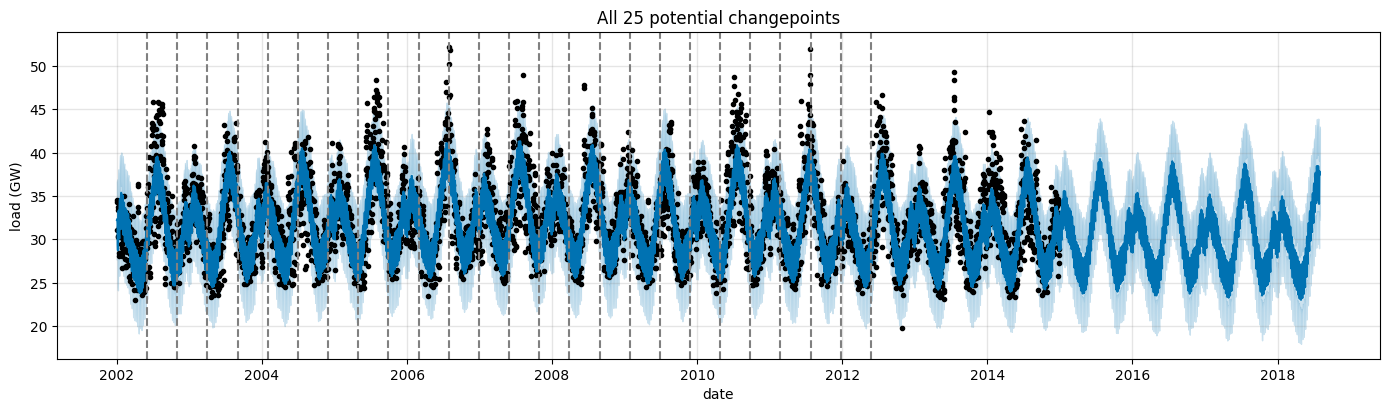

In [21]:
fig = model.plot(forecast, figsize=(14, 4), xlabel="date", ylabel="load (GW)")
add_changepoints_to_plot(fig.gca(), model, forecast, threshold=0.0, cp_color="gray", trend=False)
fig.gca().set_title("All 25 potential changepoints")
plt.show()

The potential changepoints are evenly spaced over the first 80% of the training period, from 2002 to about the end of 2012. The last 20% has none, so that the trend at the end, which is projected into the future, rests on more than a few months of data. The share is set with `changepoint_range` (default 0.8); `Prophet(changepoint_range=0.9)` places the potential changepoints in the first 90%, useful when the trend changes close to the end.

The estimated rate changes $\delta_j$ are in `model.params["delta"]`, in the scaled units of the fit.

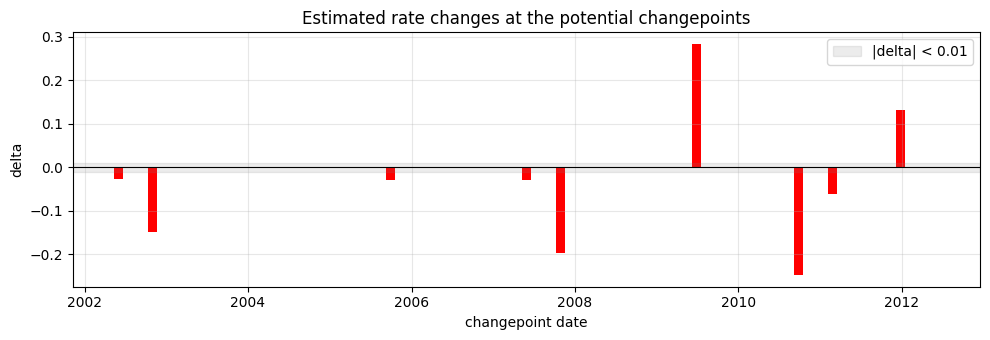

9 of 25 changepoints have |delta| > 0.01


In [22]:
delta_hat = model.params["delta"].mean(axis=0)
threshold = 0.01
used = np.abs(delta_hat) > threshold

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(model.changepoints, delta_hat, width=40, color=np.where(used, "red", "gray"))
ax.axhspan(-threshold, threshold, color="gray", alpha=0.15, label=f"|delta| < {threshold}")
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Estimated rate changes at the potential changepoints", xlabel="changepoint date", ylabel="delta")
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()
print(f"{used.sum()} of {len(delta_hat)} changepoints have |delta| > {threshold}")

The Laplace prior has set most rate changes to practically zero. Nine of the 25 changepoints exceed $|\delta_j| = 0.01$, and five of them are clearly larger. The positive change in mid-2009 ends the recession drop, the negative ones at the end of 2007 and the end of 2010 start a fall, and the positive change at the end of 2011 makes the last decline less steep.

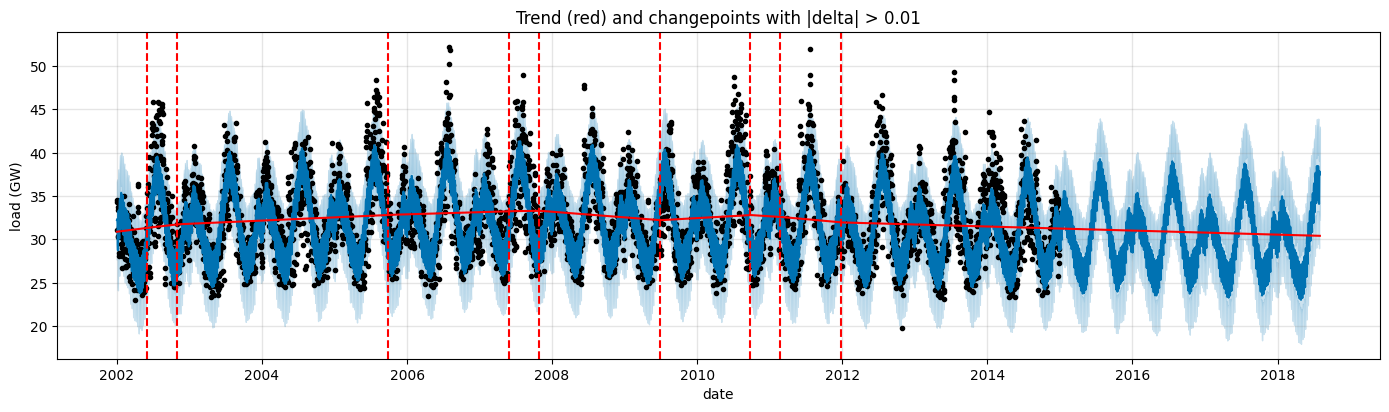

In [23]:
fig = model.plot(forecast, figsize=(14, 4), xlabel="date", ylabel="load (GW)")
add_changepoints_to_plot(fig.gca(), model, forecast, threshold=threshold, cp_color="red", trend=True)
fig.gca().set_title(f"Trend (red) and changepoints with |delta| > {threshold}")
plt.show()

The red trend line bends only at the nine red changepoints. Between them, it is straight. After the last one (end of 2011), it continues with the same slope through the last three years of training data and the whole test period.

## Adjusting the trend flexibility

If the trend follows the data too closely (overfitting) or misses a change of growth (underfitting), the prior scale $\tau$ = `changepoint_prior_scale` is the main control. We refit with $\tau = 0.5$ (ten times the default) and $\tau = 0.001$, and also with a single changepoint placed by hand through the `changepoints` argument.

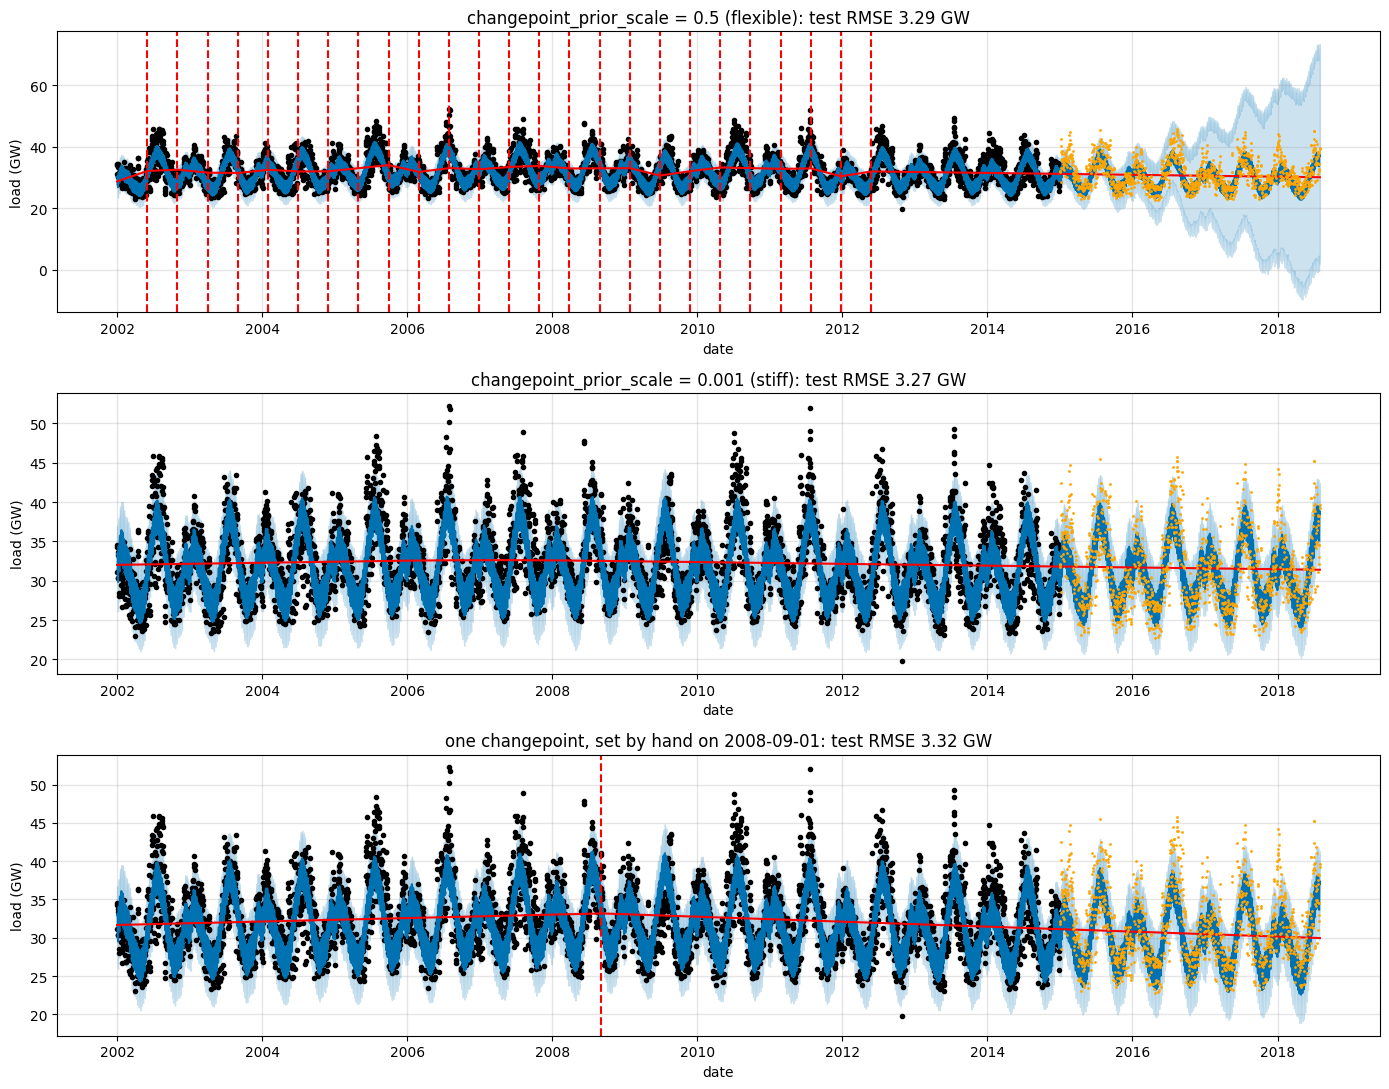

In [24]:
variants = [("changepoint_prior_scale = 0.5 (flexible)", dict(changepoint_prior_scale=0.5)),
            ("changepoint_prior_scale = 0.001 (stiff)", dict(changepoint_prior_scale=0.001)),
            ("one changepoint, set by hand on 2008-09-01", dict(changepoints=["2008-09-01"]))]

fig, axes = plt.subplots(3, 1, figsize=(14, 11))
for ax, (title, options) in zip(axes, variants):
    m_var = Prophet(**options)
    fc_var = m_var.fit(train).predict(future)
    m_var.plot(fc_var, ax=ax, xlabel="date", ylabel="load (GW)")
    add_changepoints_to_plot(ax, m_var, fc_var, threshold=threshold, cp_color="red", trend=True)
    ax.plot(test["ds"], test["y"], ".", color="orange", ms=2)
    rmse = np.sqrt(mse(test["y"], fc_var.loc[in_test, "yhat"]))
    ax.set_title(f"{title}: test RMSE {rmse:.2f} GW")
plt.tight_layout(); plt.show()

- With $\tau = 0.5$, more than 20 changepoints are used, and the trend wiggles from year to year. Because the simulated future changepoints are now as large as these past ones, the 90% interval widens to an absurd range, from about $-10$ to $70$ GW, by 2018. The point forecast is hardly worse than before (test RMSE 3.29 GW): the trend wiggles are small compared with the seasonal swings.
- With $\tau = 0.001$, the trend is almost a straight, slightly falling line, and the test RMSE is 3.27 GW.
- With a single changepoint on 1 September 2008, near the start of the financial crisis, the trend rises until then and falls after it. The fall is extrapolated over the test period, where the forecast is the lowest of the three (test RMSE 3.32 GW). The changepoint date is our choice here, so the result is only as good as that choice.

For this series, the trend moves by only a few gigawatts in 13 years, so its flexibility changes the point forecasts little. It changes the intervals a lot.

## Choosing the flexibility by cross-validation

Which $\tau$ is best cannot be read from the fit, since a more flexible trend always fits the history better, and it must not be read from the test period either. As in the earlier chapters, we judge forecasts of data the model has not seen, within the training period. Prophet's `cross_validation` does **rolling-origin evaluation**: it fits the model on the data up to a cutoff date, forecasts the next `horizon` days, moves the cutoff forward by `period` days, and repeats. The first cutoff leaves `initial` days for training. (`prophet.diagnostics.performance_metrics` would also break the errors down by forecast horizon.)

On the training period 2002-2014, we use five years of initial training data, cutoffs every 180 days, and a one-year horizon. The last column is the test RMSE of the same model fitted to the whole training period, which the choice must not see, shown only to check the choice afterwards.

In [25]:
cv_rows = {}
for tau in [0.001, 0.01, 0.05, 0.5]:
    m_cv = Prophet(changepoint_prior_scale=tau).fit(train)
    cv = cross_validation(m_cv, initial="1825 days", period="180 days", horizon="365 days", disable_tqdm=True)
    test_pred = m_cv.predict(test[["ds"]])["yhat"]
    cv_rows[tau] = {"cutoffs": cv["cutoff"].nunique(), **accuracy(cv["y"], cv["yhat"]),
                    "coverage 80% (%)": coverage(cv["y"], cv),
                    "test RMSE": np.sqrt(mse(test["y"], test_pred))}
pd.DataFrame(cv_rows).T.rename_axis("changepoint_prior_scale").round(3)

,cutoffs,RMSE,MAE,MAPE (%),coverage 80% (%),test RMSE
changepoint_prior_scale,,,,,,
0.001,15.0,3.057,2.412,7.480,76.365,3.267
0.010,15.0,3.017,2.276,6.871,78.301,3.273
0.050,15.0,3.163,2.408,7.270,75.726,3.272
0.500,15.0,3.198,2.437,7.365,82.283,3.290


Each value of $\tau$ is evaluated on the same 15 cutoffs within the training period.

- The smaller $\tau = 0.01$ has the lowest cross-validated RMSE (3.02 GW) and MAPE (6.9%); the default $\tau = 0.05$ has 3.16 GW and 7.3%, and the flexible $\tau = 0.5$ is the worst. The 80% intervals cover 76% to 82% of the observations, close to the nominal coverage.
- On the test period, all four values give practically the same RMSE, between 3.27 and 3.29 GW. The choice made by cross-validation does no harm, but it does not matter much either: most of the error is weather, which no trend setting can fix.

Choosing $\tau$ by cross-validation on the training period is the honest counterpart of the visual comparison above.

## Hourly data: the daily cycle

With hourly time stamps, Prophet also fits a **daily seasonality** (period 1 day, Fourier order 4). To keep the fit short, we use the hourly load of the last three training years, 2012-2014 (about 26,000 values), and forecast two weeks of the test period, one in winter and one in summer.

seasonalities: {'yearly': (365.25, 10), 'weekly': (7, 3), 'daily': (1, 4)}


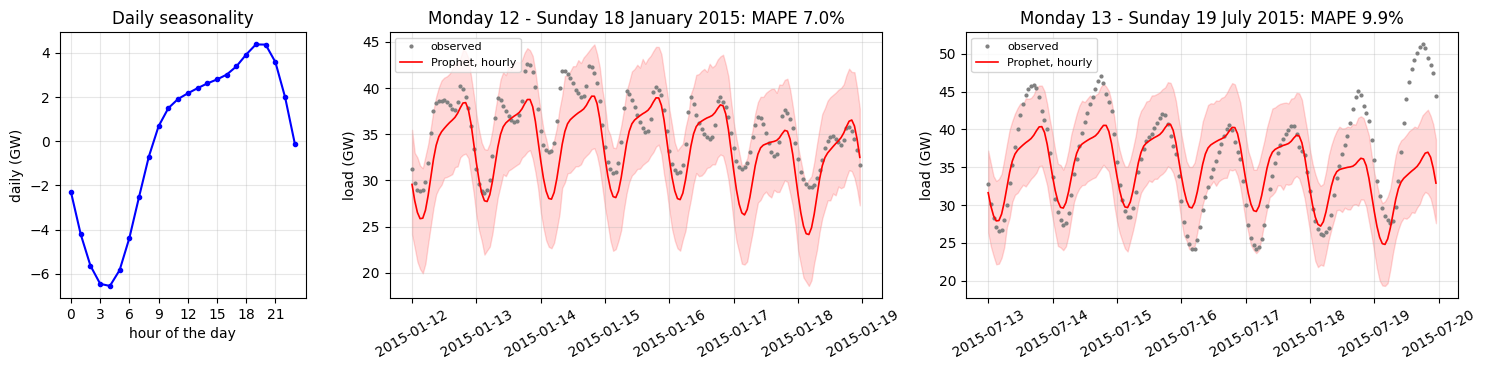

In [26]:
hourly_train = pjme_hourly["2012-01-01":"2014-12-31"]
model_h = Prophet(interval_width=0.90).fit(pd.DataFrame({"ds": hourly_train.index, "y": hourly_train.to_numpy()}))
print("seasonalities:", {name: (s["period"], s["fourier_order"]) for name, s in model_h.seasonalities.items()})

weeks = [("2015-01-12", "Monday 12 - Sunday 18 January 2015"), ("2015-07-13", "Monday 13 - Sunday 19 July 2015")]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1, 2, 2]})
one_day = model_h.predict(pd.DataFrame({"ds": pd.date_range("2015-01-12", periods=24, freq="h")}))
axes[0].plot(range(24), one_day["daily"], "o-", color="blue", ms=3)
axes[0].set(title="Daily seasonality", xlabel="hour of the day", ylabel="daily (GW)", xticks=range(0, 24, 3))
axes[0].grid(alpha=0.3)
for ax, (start, title) in zip(axes[1:], weeks):
    week = pjme_hourly[start:pd.Timestamp(start) + pd.Timedelta(hours=7 * 24 - 1)]
    fc_h = model_h.predict(pd.DataFrame({"ds": week.index}))
    ax.plot(week.index, week, "o", color="gray", ms=2, label="observed")
    ax.plot(fc_h["ds"], fc_h["yhat"], color="red", lw=1.2, label="Prophet, hourly")
    ax.fill_between(fc_h["ds"], fc_h["yhat_lower"], fc_h["yhat_upper"], color="red", alpha=0.15)
    ax.set(title=f"{title}: MAPE {mape(week, fc_h['yhat']):.1f}%", ylabel="load (GW)")
    ax.tick_params(axis="x", labelrotation=30); ax.grid(alpha=0.3); ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

The daily seasonality has its minimum at about 4 a.m. ($-6.6$ GW) and its maximum in the evening at about 7 p.m. ($+4.4$ GW). With the yearly and weekly components, the model forecasts the two weeks with a MAPE of 7.0% in January and 9.9% in July.

The model has **one daily shape for the whole year**, and the two weeks show its limit. In January, the observed load has two peaks a day, in the morning (heating and lighting as people get up) and in the evening, but the forecast has only the evening peak. In July, the observed peak comes in the late afternoon (air conditioning) and is higher than the forecast on the hot days, up to 51 GW on Sunday 19 July against a forecast of about 37 GW. The additive model also adds the same daily swing in every season, while the real swing is much larger in summer. A tree ensemble (Chapter 14) learns such interactions between hour and month from the data. Prophet needs them specified.

> **Try it yourself**
>
> Prophet can fit a separate seasonal component for each part of the year, with a **conditional seasonality**. Add boolean columns `summer` (June to September) and `winter` (the other months) to the hourly training data and to the forecast dates, create the model with `Prophet(daily_seasonality=False)`, and add `m.add_seasonality(name="daily_summer", period=1, fourier_order=4, condition_name="summer")` and the same for `winter`. How much does the MAPE of the two weeks change?

---

# Summary

**The Prophet model**: $\ y(t) = g(t) + s(t) + h(t) + \varepsilon_t$, a regression on functions of time, fitted by MAP estimation in Stan.

- **Trend** $g(t)$: piecewise linear, with rate changes $\delta_j$ at 25 potential changepoints in the first 80% of the history, shrunk by a Laplace (lasso) prior with scale `changepoint_prior_scale`; or logistic, saturating at a user-supplied `cap` (and `floor`). In the forecast period, the last rate continues, and simulated future changepoints widen the intervals.
- **Seasonality** $s(t)$: Fourier series with period $P$ and order $N$ (yearly $N = 10$, weekly $N = 3$, daily $N = 4$), switched on according to the data frequency.
- **Holidays and events** $h(t)$: one indicator per event and per day of its window, listed in a `holiday`/`ds` data frame that covers both history and forecast period; `add_country_holidays` adds national holidays.
- **Multiplicative seasonality** $y(t) = g(t)(1 + s(t) + h(t)) + \varepsilon_t$ for seasonal swings that grow with the level; a log transform with additive seasonality is the alternative.
- **Workflow**: a `ds`/`y` data frame, `Prophet(...).fit`, `make_future_dataframe`, `predict`, `plot` and `plot_components`. Choose the options by forecast error on held-out data, with `cross_validation` and `performance_metrics`, not by the fit.
- **Limits**: Prophet has no lagged values of $y$ and assumes independent errors. When the residuals are autocorrelated, short-horizon forecasts ignore information that an ARIMA model would use, and the intervals are too narrow.

---
# Additional Case Studies

## Saturating forecasts: Logistic growth model

### The Mauna Loa CO$_2$ series

The file `data/co2_mauna_loa.csv` holds the monthly mean atmospheric CO$_2$ concentration at the Mauna Loa observatory in Hawaii, in parts per million (ppm), from January 1959 to December 1997 (the `co2` data set of R). We train on 1959-1993 and test on 1994-1997.

training: 1959-01-01 to 1993-12-01 (420 months)
test:     1994-01-01 to 1997-12-01 (48 months)


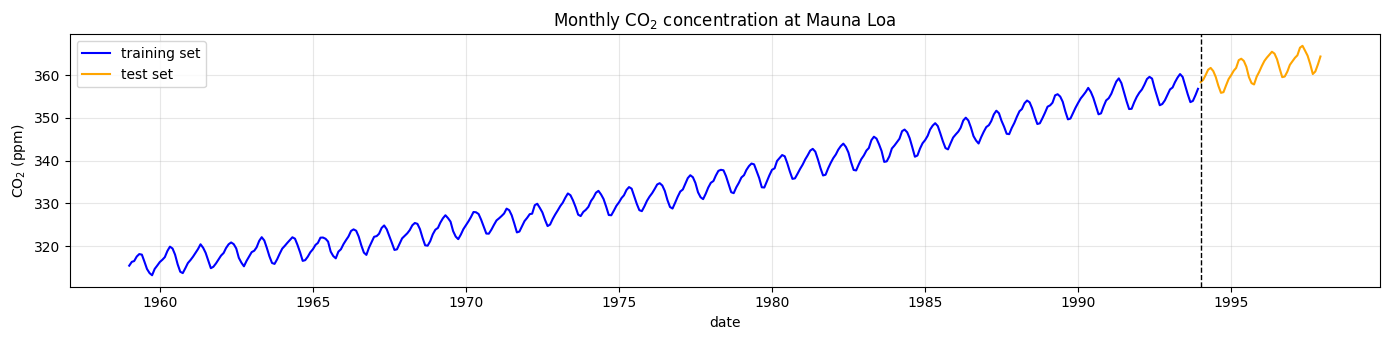

In [27]:
co2 = pd.read_csv("data/co2_mauna_loa.csv", parse_dates=["ds"])
split = pd.Timestamp("1994-01-01")
train_co2 = co2[co2["ds"] < split].copy()
test_co2 = co2[co2["ds"] >= split].copy()
print(f"training: {train_co2['ds'].iloc[0].date()} to {train_co2['ds'].iloc[-1].date()} ({len(train_co2)} months)")
print(f"test:     {test_co2['ds'].iloc[0].date()} to {test_co2['ds'].iloc[-1].date()} ({len(test_co2)} months)")

_, ax = plt.subplots(figsize=(14, 3.5))
ax.plot(train_co2["ds"], train_co2["y"], color="blue", label="training set")
ax.plot(test_co2["ds"], test_co2["y"], color="orange", label="test set")
ax.axvline(split, color="black", ls="--", lw=1)
ax.set(title="Monthly CO$_2$ concentration at Mauna Loa", xlabel="date", ylabel="CO$_2$ (ppm)")
ax.grid(alpha=0.3); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

The series rises steadily, slightly faster in the later decades, with a regular yearly cycle of about 6 ppm from peak to trough (the uptake of CO$_2$ by the vegetation of the northern hemisphere in summer).

### A logistic trend with a carrying capacity

For `growth="logistic"`, the training data frame needs a column `cap` with the carrying capacity at each date, and so does the future data frame. Prophet does not estimate the capacity: it must come from knowledge about the series, such as a market size. Nothing in physics caps the CO$_2$ concentration, so here the capacity is purely an assumption, and we try two values, 360 ppm (the source example) and 380 ppm, next to the linear trend.

Monthly data have no weekly or daily cycles, and Prophet turns those seasonalities off by itself. The future data frame must use `freq="MS"` (month start), as the data do.

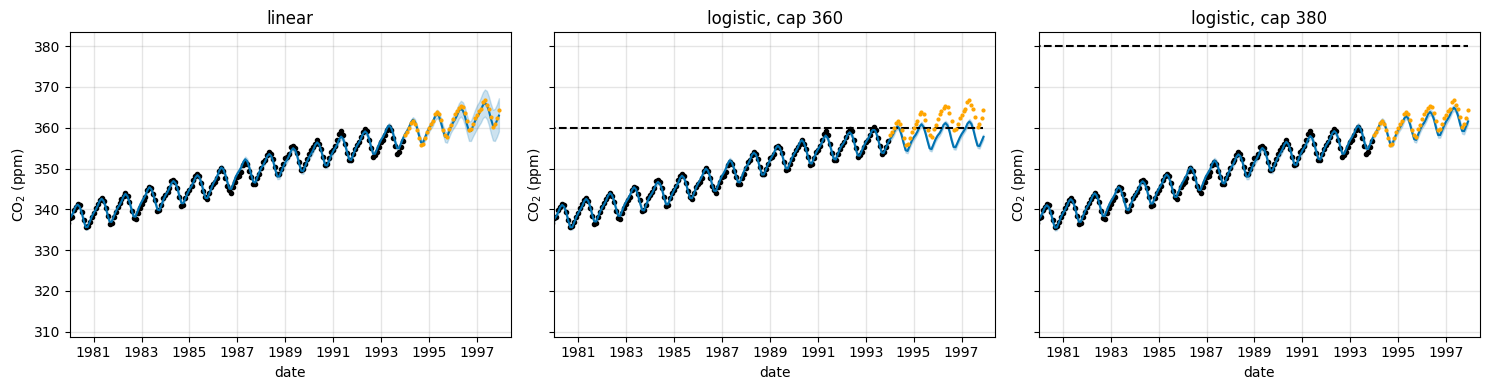

,RMSE,MAE,MAPE (%)
linear,0.590,0.502,0.139
"logistic, cap 360",3.833,3.538,0.977
"logistic, cap 380",1.316,1.127,0.311


In [28]:
future_co2 = pd.DataFrame({"ds": co2["ds"]})          # the training and test months
fits_co2 = {}
for label, cap in [("linear", None), ("logistic, cap 360", 360), ("logistic, cap 380", 380)]:
    tr, fu = train_co2.copy(), future_co2.copy()
    if cap is not None:
        tr["cap"] = cap
        fu["cap"] = cap
    m_co2 = Prophet(growth="linear" if cap is None else "logistic", interval_width=0.90).fit(tr)
    fits_co2[label] = (m_co2, m_co2.predict(fu))

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (label, (m_co2, fc)) in zip(axes, fits_co2.items()):
    m_co2.plot(fc, ax=ax, xlabel="date", ylabel="CO$_2$ (ppm)")
    ax.plot(test_co2["ds"], test_co2["y"], ".", color="orange", ms=4, label="test data")
    ax.set_title(label); ax.set_xlim(pd.Timestamp("1980-01-01"), pd.Timestamp("1998-06-01"))
plt.tight_layout(); plt.show()

in_test = future_co2["ds"] >= split
pd.DataFrame({label: accuracy(test_co2["y"], fc.loc[in_test, "yhat"])
              for label, (_, fc) in fits_co2.items()}).T.round(3)

- With **cap 360**, the trend must bend to stay below 360 ppm. The training data end just below that level, so the forecast flattens immediately, while the observed concentration keeps rising. The forecast is 3.5 ppm too low on average, and the error grows every year.
- With **cap 380**, the bend is milder: the forecast is only slightly too low, and its error is about twice that of the linear trend.
- The **linear trend** forecasts the test period best (RMSE 0.59 ppm, MAPE 0.14%).

The capacity is an assumption, and the logistic trend is only as good as that assumption. It is the right tool when a hard limit is known (a market size, a population, the capacity of a system), not as a way to make the forecast more cautious. The value of `cap` should come from such knowledge, not from trying values on the test set, as we did here only to show the effect.

### A saturating minimum

The logistic trend may also have a lower bound, given in a column `floor`; a `cap` is then still required. To show it, we turn the CO$_2$ series upside down, $400 - y$, so that it decreases, and set the floor at 40 and the capacity at 85.

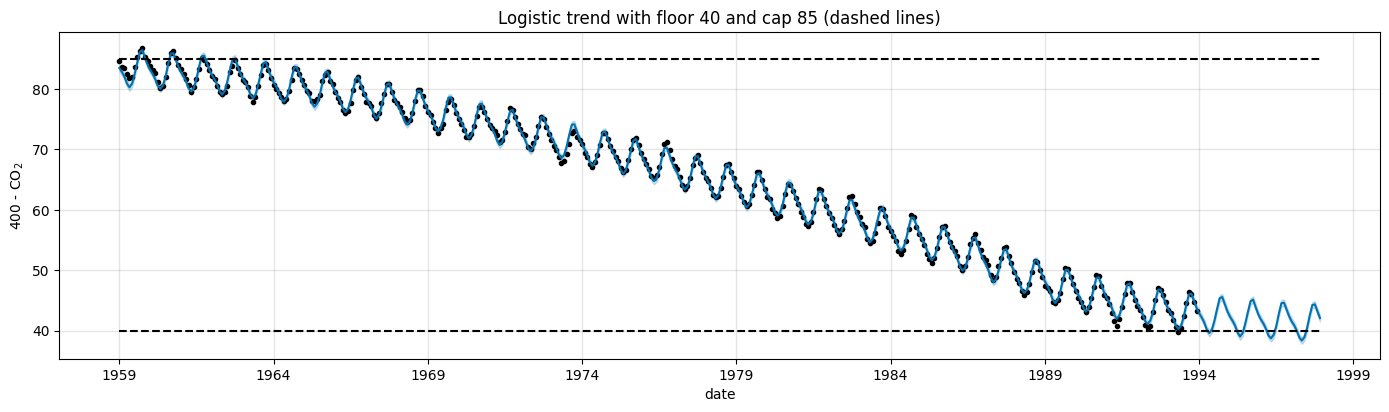

In [29]:
train_dec = train_co2.assign(y=400 - train_co2["y"], cap=85, floor=40)
future_dec = future_co2.assign(cap=85, floor=40)
m_dec = Prophet(growth="logistic").fit(train_dec)
fc_dec = m_dec.predict(future_dec)

fig = m_dec.plot(fc_dec, figsize=(14, 4), xlabel="date", ylabel="400 - CO$_2$")
fig.gca().set_title("Logistic trend with floor 40 and cap 85 (dashed lines)")
plt.show()

The trend decreases towards the floor and levels off above it. The bounds apply to the **trend only**: the seasonal cycle is added on top, so the forecast itself dips below the floor in every summer of the forecast period (to about 38). Some training observations are already below 40. If a series can truly never fall below a floor, the floor must leave room for the seasonal swings, or the model must be fitted to a transformed series.

---

## Additive and multiplicative seasonality

So far, the seasonal effects were *added* to the trend: the yearly cycle has the same size whatever the level of the series. Many series have seasonal swings that grow with the level instead. For them, Prophet offers a **multiplicative** model,

$$y(t) = g(t)\,\bigl(1 + s(t) + h(t)\bigr) + \varepsilon_t,$$

where $s(t)$ and $h(t)$ are now fractions of the trend: $s(t) = 0.1$ means 10% above the trend. It is selected with `seasonality_mode="multiplicative"`.

### The airline passengers

The file `data/air_passengers.csv` holds the classic monthly totals of international airline passengers, in thousands, from January 1949 to December 1960 (the `AirPassengers` data set of R, from Box and Jenkins). We train on 1949-1957 and test on 1958-1960.

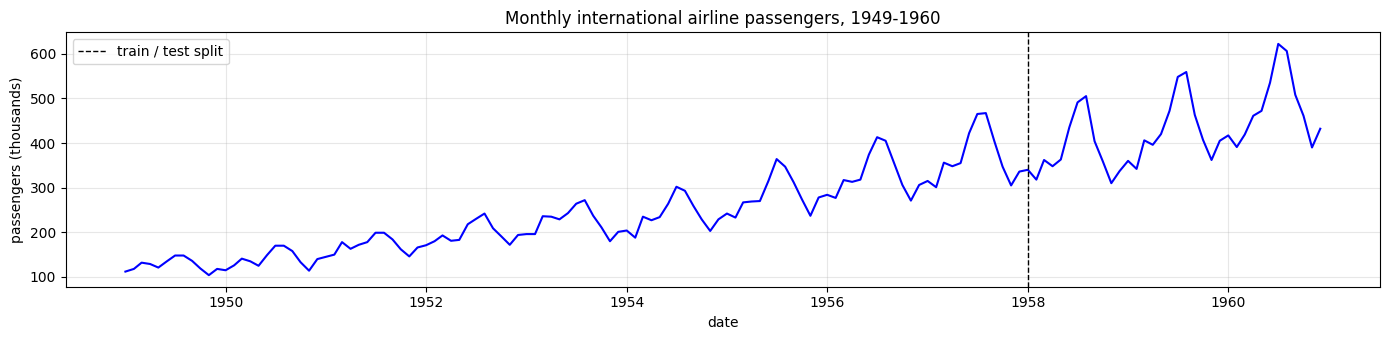

ds           1949    1950    1951    1952    1953    1954    1955    1956    1957    1958    1959    1960
mean       126.67  139.67  170.17  197.00  225.00  238.92  284.00  328.25  368.42  381.00  428.33  476.17
max - min   44.00   56.00   54.00   71.00   92.00  114.00  131.00  142.00  166.00  195.00  217.00  232.00
ratio        0.35    0.40    0.32    0.36    0.41    0.48    0.46    0.43    0.45    0.51    0.51    0.49


In [30]:
air = pd.read_csv("data/air_passengers.csv", parse_dates=["ds"])
split_air = pd.Timestamp("1958-01-01")
train_air = air[air["ds"] < split_air].copy()
test_air = air[air["ds"] >= split_air].copy()

_, ax = plt.subplots(figsize=(14, 3.5))
ax.plot(air["ds"], air["y"], color="blue")
ax.axvline(split_air, color="black", ls="--", lw=1, label="train / test split")
ax.set(title="Monthly international airline passengers, 1949-1960", xlabel="date", ylabel="passengers (thousands)")
ax.grid(alpha=0.3); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

swing = air.groupby(air["ds"].dt.year)["y"].agg(lambda v: v.max() - v.min())
level = air.groupby(air["ds"].dt.year)["y"].mean()
print(pd.DataFrame({"mean": level, "max - min": swing, "ratio": swing / level}).T.round(2).to_string())

The number of passengers grows almost four-fold, from an average of 127 thousand a month in 1949 to 476 thousand in 1960, and the seasonal swing (the largest minus the smallest month of each year) grows with it, from 44 to 232 thousand. Relative to the yearly mean, the swing stays between about 0.3 and 0.5. This is the signature of multiplicative seasonality.

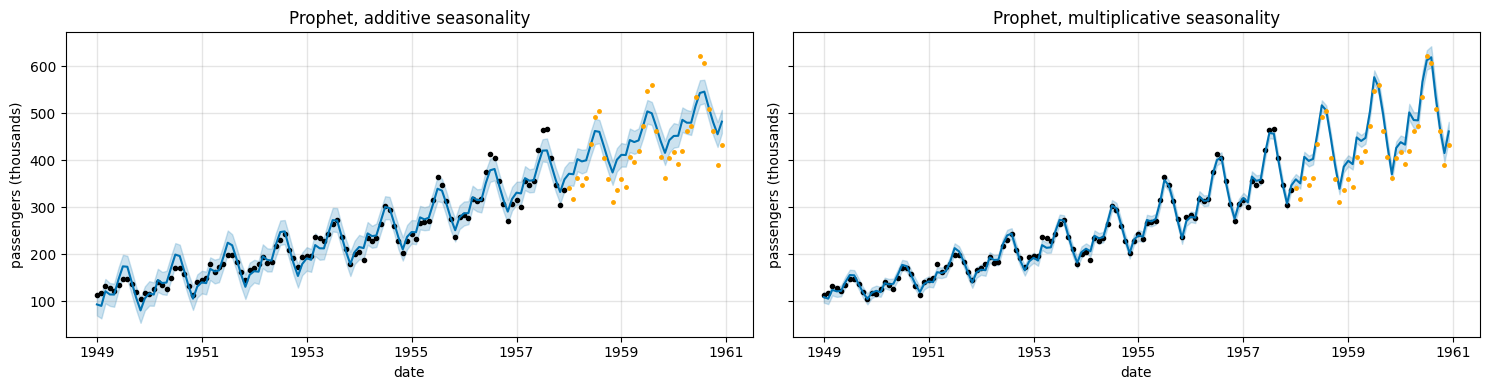

In [31]:
future_air = pd.DataFrame({"ds": air["ds"]})
m_add = Prophet(seasonality_mode="additive", interval_width=0.90).fit(train_air)
m_mul = Prophet(seasonality_mode="multiplicative", interval_width=0.90).fit(train_air)
fc_add = m_add.predict(future_air)
fc_mul = m_mul.predict(future_air)

fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
for ax, (label, m_air, fc) in zip(axes, [("additive", m_add, fc_add), ("multiplicative", m_mul, fc_mul)]):
    m_air.plot(fc, ax=ax, xlabel="date", ylabel="passengers (thousands)")
    ax.plot(test_air["ds"], test_air["y"], ".", color="orange", ms=5, label="test data")
    ax.set_title(f"Prophet, {label} seasonality")
plt.tight_layout(); plt.show()

The **additive** model has one seasonal pattern of fixed size, fitted to the average swing of 1949-1957. It is too large at the start (in 1949-1950, the fitted peaks and troughs overshoot the data) and too small at the end: in the test years, the summer peaks lie far above the forecast band. The **multiplicative** model scales the seasonal pattern with the trend and follows both the small swings of 1949 and the large swings of 1958-1960. Both models over-forecast the test period somewhat, most visibly in 1958, when the growth of air travel slowed down.

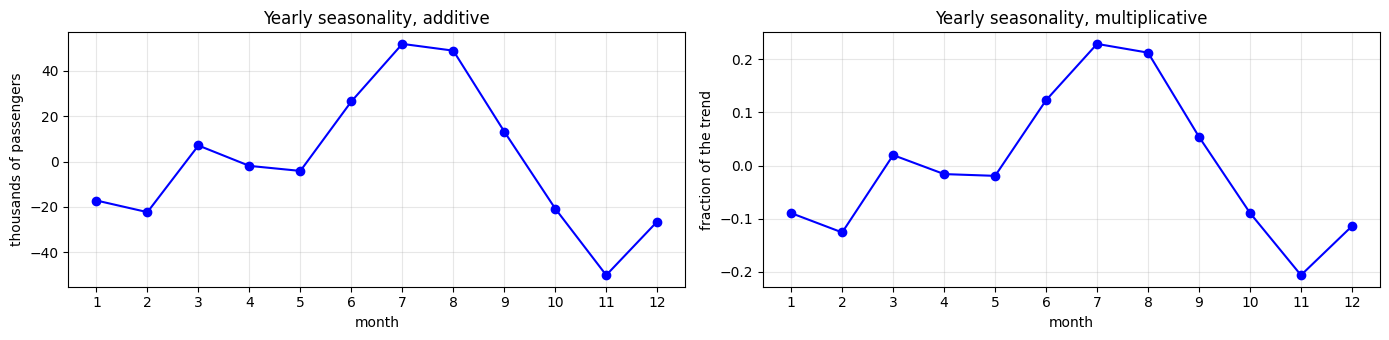

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
for ax, (label, fc, unit) in zip(axes, [("additive", fc_add, "thousands of passengers"),
                                         ("multiplicative", fc_mul, "fraction of the trend")]):
    first_year = fc.iloc[:12]
    ax.plot(first_year["ds"].dt.month, first_year["yearly"], "o-", color="blue")
    ax.set(title=f"Yearly seasonality, {label}", xlabel="month", ylabel=unit, xticks=range(1, 13))
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

The two yearly components have the same shape, with a summer peak in July and August and a low in November, but different units. The additive component is in thousands of passengers, from $-50$ to $+52$ in every year. The multiplicative component is a fraction of the trend, from $-0.21$ to $+0.23$: a swing of about 44% of the trend, close to the ratios in the table above, which in thousands of passengers grows with the trend.

### Comparison on the test period

Besides the two Prophet models, we fit the additive model to the logarithm of the series and transform its forecast back with $e^{\hat y}$: the logarithm turns a multiplicative structure into an additive one. The benchmark is the **seasonal naive** forecast of Chapter 6, which repeats the last observed year (1957) in each test year. Besides the accuracy, we report the share of test months that fall inside the 90% prediction interval.

In [33]:
m_log = Prophet(seasonality_mode="additive", interval_width=0.90).fit(train_air.assign(y=np.log(train_air["y"])))
fc_log = m_log.predict(future_air)
fc_log[["yhat", "yhat_lower", "yhat_upper"]] = np.exp(fc_log[["yhat", "yhat_lower", "yhat_upper"]])

in_test = future_air["ds"] >= split_air
y_test_air = test_air["y"].to_numpy()
snaive = np.tile(train_air["y"].iloc[-12:].to_numpy(), 3)

rows = {"seasonal naive": accuracy(y_test_air, snaive)}
for label, fc in [("Prophet, additive", fc_add), ("Prophet, multiplicative", fc_mul),
                  ("Prophet, additive on log(y)", fc_log)]:
    t = fc[in_test]
    covered = (y_test_air >= t["yhat_lower"].to_numpy()) & (y_test_air <= t["yhat_upper"].to_numpy())
    rows[label] = {**accuracy(y_test_air, t["yhat"]), "coverage 90% (%)": 100 * covered.mean()}
pd.DataFrame(rows).T.round(2)

,RMSE,MAE,MAPE (%),coverage 90% (%)
seasonal naive,73.61,60.08,13.19,NaN
"Prophet, additive",44.57,39.58,9.75,27.78
"Prophet, multiplicative",33.69,29.70,7.44,19.44
"Prophet, additive on log(y)",50.27,45.78,11.18,52.78


- All three Prophet models beat the seasonal naive benchmark, which ignores the growth.
- The **multiplicative** model is the most accurate: an RMSE of about 34 thousand passengers, against 45 for the additive model, and a MAPE of 7.4% against 9.8%.
- The **additive model on $\log(y)$** is *worse* than both, with an RMSE of about 50. In theory, the log transform turns the multiplicative seasonality into an additive one, but it also changes the trend: a straight-line trend in $\log(y)$ is exponential growth in $y$. The training years grew fast, the test years more slowly, and the exponential trend runs away from the data. Its over-forecast grows from 36 thousand passengers a month in 1958 to 58 thousand in 1960, while the multiplicative model, with a linear trend, over-forecasts by 26 to 33 thousand.
- The **90% intervals cover only 19% to 56%** of the test months. Prophet's intervals combine the noise of the fit and the uncertainty of future changepoints. Both are small here, because the fit is very close and the training trend has few changepoints. They do not anticipate the slowdown of 1958, which is a change of the trend at the very start of the forecast period.

The seasonality mode is a property of the data that a plot of the series usually reveals. The trend that comes with it, linear in $y$ or linear in $\log(y)$, matters as much for a three-year forecast.

| `seasonality_mode` | When to use |
|---|---|
| `"additive"` (default) | the seasonal swings have about the same size at every level of the series |
| `"multiplicative"` | the seasonal swings grow or shrink in proportion to the level |

The mode can also be set per component. `m.add_seasonality(name="weekly", period=7, fourier_order=3, mode="additive")`, for instance, keeps a weekly seasonality additive in a model whose other components are multiplicative. The same method adds seasonalities with other periods, such as a monthly cycle (`period=30.5`).